# Transformer do zero: *Attention Is All You Need* com toy dataset

**Objetivo:** implementar o Transformer encoder-decoder do paper, peça por peça, e **ver** o efeito de cada conceito: multi-head attention, residual connections, layer normalization, masking, dropout e label smoothing.

**Como usar**
1. Rode as células em ordem. Cada seção tem **explicação → `# TODO` → teste**.
2. Implemente o TODO (`raise NotImplementedError` some quando você terminar) e rode o teste. Só avance quando aparecer ✅.
3. Os testes comparam sua implementação com as referências oficiais do PyTorch (`F.scaled_dot_product_attention`, `nn.MultiheadAttention`, `nn.LayerNorm`, `F.cross_entropy`).
4. Depois de tudo passar, treine e faça os **experimentos** da seção 15. É aí que o entendimento se consolida.

**Tarefa toy:** inverter uma sequência de dígitos (`3 1 4 1 5 → 5 1 4 1 3`). Tem resposta exata, treina em poucos minutos (CPU serve) e só funciona se a atenção alinhar posições. Os comprimentos variam, então o padding mask é exercitado de verdade.

**Hiperparâmetros do paper (modelo base):** d_model=512, h=8, d_ff=2048, N=6, dropout=0.1, label smoothing=0.1, Adam (β1=0.9, β2=0.98, ε=1e-9), warmup=4000. Aqui usamos uma versão pequena do mesmo desenho.

**Ordem de implementação:** máscaras → atenção → multi-head → LayerNorm → posição → FFN → residual+LN+dropout → camadas → modelo → label smoothing → LR schedule → decode.

**Ambiente:** PyTorch 2.x, NumPy e Matplotlib (já vêm no Google Colab). Localmente: `uv pip install torch numpy matplotlib jupyter`.

In [35]:
import math, random, time
from dataclasses import dataclass
from typing import Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)

torch 2.6.0+cu124 | device: cuda


In [36]:
@dataclass
class Config:
    # arquitetura (paper base: d_model=512, n_heads=8, d_ff=2048, n_layers=6)
    d_model: int = 64
    n_heads: int = 4
    d_ff: int = 256
    n_layers: int = 2
    dropout: float = 0.1
    pre_norm: bool = False          # False = post-LN (paper) | True = pre-LN (padrão moderno)
    # treino
    label_smoothing: float = 0.1
    warmup_steps: int = 400
    lr_factor: float = 0.5          # multiplica a curva "noam" (o paper usa 1.0 com d_model=512)
    batch_size: int = 128
    steps: int = 4000
    train_size: Optional[int] = None  # None = dados infinitos | int = pool fixo (para ver overfitting)
    # dados
    min_len: int = 3
    max_len: int = 12

cfg = Config()
cfg

Config(d_model=64, n_heads=4, d_ff=256, n_layers=2, dropout=0.1, pre_norm=False, label_smoothing=0.1, warmup_steps=400, lr_factor=0.5, batch_size=128, steps=4000, train_size=None, min_len=3, max_len=12)

## 0. Dados

Vocabulário: `PAD=0`, `BOS=1`, `EOS=2` e os dígitos 0-9 viram os tokens 3-12.

O decoder recebe `tgt_in = [BOS] + alvo` e deve prever `tgt_out = alvo + [EOS]`. Isso é o *"shifted right"* do paper: em cada posição, o decoder vê os tokens anteriores e prevê o próximo.

Com `train_size=None` os exemplos são gerados na hora (nunca há overfitting). Com `train_size=N` o treino usa um pool fixo de N exemplos e a validação nunca vaza para o treino. Esse segundo modo é o que mostra o efeito de dropout e label smoothing.

In [37]:
PAD, BOS, EOS = 0, 1, 2
N_DIGITS = 10
VOCAB = 3 + N_DIGITS   # PAD, BOS, EOS + dígitos (token = dígito + 3)

def make_example(min_len, max_len):
    n = random.randint(min_len, max_len)
    digits = [random.randint(0, N_DIGITS - 1) + 3 for _ in range(n)]
    return digits, digits[::-1]          # (src, tgt): inversão

def collate(examples):
    """Lista de (src, tgt) -> tensores com padding.
    src:     [B, S]  dígitos + PAD
    tgt_in:  [B, T]  BOS + tgt       (entrada do decoder)
    tgt_out: [B, T]  tgt + EOS       (alvo da previsão)"""
    B = len(examples)
    S = max(len(s) for s, _ in examples)
    T = max(len(t) for _, t in examples) + 1
    src = torch.full((B, S), PAD, dtype=torch.long)
    tgt_in = torch.full((B, T), PAD, dtype=torch.long)
    tgt_out = torch.full((B, T), PAD, dtype=torch.long)
    for i, (s, t) in enumerate(examples):
        src[i, :len(s)] = torch.tensor(s)
        tgt_in[i, :len(t) + 1] = torch.tensor([BOS] + t)
        tgt_out[i, :len(t) + 1] = torch.tensor(t + [EOS])
    return src, tgt_in, tgt_out

class Data:
    def __init__(self, cfg, n_val=500):
        self.cfg = cfg
        random.seed(1234)
        val, seen = [], set()
        while len(val) < n_val:
            s, t = make_example(cfg.min_len, cfg.max_len)
            if tuple(s) not in seen:
                seen.add(tuple(s)); val.append((s, t))
        self.val = val
        self.pool = None
        if cfg.train_size is not None:
            pool = []
            while len(pool) < cfg.train_size:
                s, t = make_example(cfg.min_len, cfg.max_len)
                if tuple(s) not in seen:          # exemplo de validação nunca entra no treino
                    pool.append((s, t))
            self.pool = pool
        set_seed(0)

    def train_batch(self):
        if self.pool is None:
            ex = [make_example(self.cfg.min_len, self.cfg.max_len) for _ in range(self.cfg.batch_size)]
        else:
            ex = random.sample(self.pool, self.cfg.batch_size)
        return [t.to(device) for t in collate(ex)]

In [38]:
src, tgt_in, tgt_out = collate([make_example(3, 6) for _ in range(3)])
print("src\n", src); print("tgt_in\n", tgt_in); print("tgt_out\n", tgt_out)

src
 tensor([[ 9,  3,  7, 11, 10,  9],
        [10,  8, 12,  6, 11,  0],
        [ 7,  5,  4, 12,  0,  0]])
tgt_in
 tensor([[ 1,  9, 10, 11,  7,  3,  9],
        [ 1, 11,  6, 12,  8, 10,  0],
        [ 1, 12,  4,  5,  7,  0,  0]])
tgt_out
 tensor([[ 9, 10, 11,  7,  3,  9,  2],
        [11,  6, 12,  8, 10,  2,  0],
        [12,  4,  5,  7,  2,  0,  0]])


## 1. Máscaras (masking)

Há dois motivos para mascarar, e é importante não confundir:

- **Padding mask:** sequências do batch têm tamanhos diferentes e completamos com `PAD`. Esses tokens não carregam informação, então nenhuma query deve atender a eles (como *key*).
- **Causal mask (decoder):** na posição *i*, o decoder só pode ver as posições ≤ *i*. Sem isso ele "cola" a resposta (o token que deve prever está na própria entrada) e a loss de treino despenca sem aprender nada útil.

**Convenção usada neste notebook:** `True` = *pode atender*. É a mesma de `F.scaled_dot_product_attention`. Atenção: `nn.MultiheadAttention` usa a convenção **oposta** (`True` = bloqueado).

Formas (para fazer broadcast com os scores `[B, h, Lq, Lk]`): padding `[B,1,1,Lk]`, causal `[1,1,T,T]`.

In [39]:
def make_padding_mask(seq, pad_idx=PAD):
    """seq: [B, L] -> [B, 1, 1, L] bool; True onde o token NÃO é padding."""
    return (seq != pad_idx).unsqueeze(1).unsqueeze(2)

def make_causal_mask(T, device=None):
    """-> [1, 1, T, T] bool; True onde a query i pode ver a key j (j <= i)."""
    return torch.tril(torch.ones((T, T), dtype=torch.bool, device=device)).unsqueeze(0).unsqueeze(0)

def make_tgt_mask(tgt, pad_idx=PAD):
    """Máscara da self-attention do decoder = padding E causal -> [B, 1, T, T]."""
    padding = make_padding_mask(tgt, pad_idx=pad_idx)
    causal = make_causal_mask(tgt.size(1), device=tgt.device)
    return padding & causal

In [40]:
seq = torch.tensor([[5, 6, 7, PAD, PAD], [5, 6, 7, 8, 9]])
pm = make_padding_mask(seq)
assert pm.shape == (2, 1, 1, 5) and pm.dtype == torch.bool
assert pm[0, 0, 0].tolist() == [True, True, True, False, False]
cm = make_causal_mask(4)
assert cm.shape == (1, 1, 4, 4)
assert cm[0, 0].tolist() == [[True, False, False, False], [True, True, False, False],
                             [True, True, True, False], [True, True, True, True]]
tm = make_tgt_mask(seq)
assert tm.shape == (2, 1, 5, 5)
assert tm[0, 0, 4, 3] == False      # key de padding não é visto
assert tm[0, 0, 1, 2] == False      # futuro não é visto
assert tm[0, 0, 2, 1] == True
print("✅ máscaras ok")

✅ máscaras ok


## 2. Scaled dot-product attention

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

Pontos para pensar enquanto implementa:
- Por que dividir por $\sqrt{d_k}$? (Paper, seção 3.2.1: produtos escalares grandes empurram o softmax para regiões com gradiente minúsculo.)
- A máscara entra **antes** do softmax, trocando o score das posições proibidas por um valor muito negativo. Assim o peso delas vira 0 e o resto continua somando 1.
- O dropout da atenção (paper, seção 5.4 fala em dropout nas sub-camadas; muitas implementações também aplicam nos pesos) age sobre os pesos, depois do softmax.

In [41]:
def scaled_dot_product_attention(q, k, v, mask=None, dropout=None):
    """
    q: [B, h, Lq, d_k]   k: [B, h, Lk, d_k]   v: [B, h, Lk, d_v]
    mask: bool broadcastável para [B, h, Lq, Lk]; True = pode atender
    dropout: nn.Dropout ou None (aplicado aos pesos de atenção)
    Retorna (saída [B, h, Lq, d_v], pesos [B, h, Lq, Lk])
    """
    # TODO: 1) scores = q @ k^T / sqrt(d_k)
    #       2) onde mask é False -> score muito negativo
    #       3) softmax no último eixo   4) dropout nos pesos   5) pesos @ v
    d_k = q.size(-1)
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float('-inf'))
    attn_weights = F.softmax(scores, dim=-1)
    if dropout is not None:
        attn_weights = dropout(attn_weights)
    output = torch.matmul(attn_weights, v)
    return output, attn_weights

In [8]:
set_seed(0)
q = torch.randn(2, 4, 5, 8); k = torch.randn(2, 4, 5, 8); v = torch.randn(2, 4, 5, 8)
mask = make_causal_mask(5)
out, w = scaled_dot_product_attention(q, k, v, mask)
ref = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)   # referência oficial do PyTorch
assert out.shape == (2, 4, 5, 8) and w.shape == (2, 4, 5, 5)
assert torch.allclose(out, ref, atol=1e-5), "difere do PyTorch"
assert torch.allclose(w.sum(-1), torch.ones(2, 4, 5), atol=1e-5), "pesos devem somar 1"
assert (w.masked_fill(mask, 0) == 0).all(), "peso em posição mascarada deve ser 0"
print("✅ atenção ok")

✅ atenção ok


## 3. Multi-head attention

Em vez de uma atenção com vetores de tamanho `d_model`, o paper usa **h cabeças** com `d_k = d_model / h`, cada uma com suas próprias projeções, e concatena os resultados. Cada cabeça pode especializar-se em um tipo de relação.

**Detalhe de implementação:** o paper descreve `h` matrizes $W_i^Q$ de tamanho `d_model × d_k`. Isso é equivalente a **uma** `nn.Linear(d_model, d_model)` cujas saídas são fatiadas em h blocos de `d_k` (é o que fazemos aqui, e é bem mais rápido).

A mesma classe serve para os três usos do Transformer: *self-attention do encoder* (`x_q = x_kv`), *self-attention mascarada do decoder* e *cross-attention* (`x_q` vem do decoder, `x_kv` vem do encoder).

In [42]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.0):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_k = n_heads, d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.attn = None            # guarda os pesos da última chamada (para visualizar)

    def forward(self, x_q, x_kv, mask=None):
        """x_q: [B, Lq, d_model]; x_kv: [B, Lk, d_model]. Retorna [B, Lq, d_model]."""
        # Projeta queries a partir da sequência consultada e keys/values da memória.
        B, Lq, _ = x_q.shape
        Lk = x_kv.size(1)
        q = self.W_q(x_q).view(B, Lq, self.h, self.d_k).transpose(1, 2)
        k = self.W_k(x_kv).view(B, Lk, self.h, self.d_k).transpose(1, 2)
        v = self.W_v(x_kv).view(B, Lk, self.h, self.d_k).transpose(1, 2)

        # Cada cabeça calcula atenção independentemente.
        out, weights = scaled_dot_product_attention(q, k, v, mask, self.dropout)
        self.attn = weights.detach()

        # Reúne as cabeças e mistura suas informações com a projeção de saída.
        out = out.transpose(1, 2).contiguous().view(B, Lq, self.h * self.d_k)
        return self.W_o(out)

In [43]:
set_seed(0)
d, h = 16, 4
mha = MultiHeadAttention(d, h, dropout=0.0).eval()
ref = nn.MultiheadAttention(d, h, dropout=0.0, batch_first=True).eval()
with torch.no_grad():   # copia os pesos para comparar com a referência
    ref.in_proj_weight.copy_(torch.cat([mha.W_q.weight, mha.W_k.weight, mha.W_v.weight]))
    ref.in_proj_bias.copy_(torch.cat([mha.W_q.bias, mha.W_k.bias, mha.W_v.bias]))
    ref.out_proj.weight.copy_(mha.W_o.weight); ref.out_proj.bias.copy_(mha.W_o.bias)
x = torch.randn(2, 6, d)
cm = make_causal_mask(6)
with torch.no_grad():
    mine = mha(x, x, cm)
    # ATENÇÃO: em nn.MultiheadAttention, attn_mask=True significa "NÃO pode atender" (convenção oposta)
    theirs, _ = ref(x, x, x, attn_mask=~cm[0, 0], need_weights=False)
assert mine.shape == (2, 6, d)
assert torch.allclose(mine, theirs, atol=1e-5), "difere do nn.MultiheadAttention"
with torch.no_grad():   # cross-attention: Lq != Lk
    assert mha(torch.randn(2, 3, d), torch.randn(2, 6, d)).shape == (2, 3, d)
assert mha.attn.shape == (2, h, 3, 6)
print("✅ multi-head attention ok")

✅ multi-head attention ok


## 4. Layer normalization

Normaliza **cada vetor de token** (último eixo) para média 0 e variância 1 e depois aplica uma escala e um deslocamento aprendidos ($\gamma$, $\beta$):

$$\text{LN}(x)=\gamma\,\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}+\beta$$

Por que LayerNorm e não BatchNorm em NLP? As estatísticas de LayerNorm são calculadas por token, então não dependem do tamanho do batch nem do padding de outras amostras. Use a variância **viesada** (`unbiased=False`), como o `nn.LayerNorm`.

In [44]:
class LayerNorm(nn.Module):
    def __init__(self, d_model, eps=1e-5):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(d_model))
        self.beta = nn.Parameter(torch.zeros(d_model))
        self.eps = eps

    def forward(self, x):
        """x: [..., d_model] -> mesmo shape."""
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        normalized = (x - mean) / torch.sqrt(var + self.eps)
        return self.gamma * normalized + self.beta

In [45]:
set_seed(0)
x = torch.randn(3, 5, 16) * 4 + 2
ln = LayerNorm(16); ref = nn.LayerNorm(16)
assert torch.allclose(ln(x), ref(x), atol=1e-5), "difere do nn.LayerNorm"
y = ln(x)
assert torch.allclose(y.mean(-1), torch.zeros(3, 5), atol=1e-5)
assert torch.allclose(y.var(-1, unbiased=False), torch.ones(3, 5), atol=1e-3)
print("✅ layernorm ok")

✅ layernorm ok


## 5. Embeddings e codificação posicional

A atenção não tem noção de ordem: embaralhar os tokens só embaralha as saídas. A ordem entra somando um vetor de posição ao embedding (paper, seção 3.5):

$$PE_{(pos,2i)}=\sin\!\big(pos/10000^{2i/d_{model}}\big),\qquad PE_{(pos,2i+1)}=\cos\!\big(pos/10000^{2i/d_{model}}\big)$$

Também (seção 3.4) os embeddings são multiplicados por $\sqrt{d_{model}}$, e (seção 5.4) aplica-se **dropout na soma embedding + posição**.

In [46]:
def sinusoidal_pe(max_len, d_model):
    """Retorna [max_len, d_model] com PE[pos, 2i]=sin(...) e PE[pos, 2i+1]=cos(...)."""
    positions = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
    even_dims = torch.arange(0, d_model, 2, dtype=torch.float32)
    scales = torch.exp(even_dims * (-math.log(10000.0) / d_model))

    pe = torch.zeros(max_len, d_model, dtype=torch.float32)
    pe[:, 0::2] = torch.sin(positions * scales)
    # Em d_model ímpar, há uma coluna seno a mais que colunas cosseno.
    pe[:, 1::2] = torch.cos(positions * scales[:pe[:, 1::2].size(1)])
    return pe

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout, max_len=512):
        super().__init__()
        self.d_model = d_model
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("pe", sinusoidal_pe(max_len, d_model))   # buffer: não é parâmetro, mas acompanha .to(device)

    def forward(self, x):
        """x: [B, L, d_model] embeddings crus. Retorna dropout(x * sqrt(d_model) + PE[:L])."""
        length = x.size(1)
        pe = self.pe[:length].unsqueeze(0).to(device=x.device, dtype=x.dtype)
        x = x * math.sqrt(self.d_model) + pe
        return self.dropout(x)

In [47]:
pe = sinusoidal_pe(10, 8)
assert pe.shape == (10, 8)
assert torch.allclose(pe[0, 0::2], torch.zeros(4)) and torch.allclose(pe[0, 1::2], torch.ones(4))
assert math.isclose(pe[1, 0].item(), math.sin(1.0), rel_tol=1e-5)
assert math.isclose(pe[1, 1].item(), math.cos(1.0), rel_tol=1e-5)
assert math.isclose(pe[3, 2].item(), math.sin(3 / 10000 ** (2 / 8)), rel_tol=1e-4)
pos = PositionalEncoding(8, 0.0).eval()
z = torch.zeros(2, 4, 8)
assert torch.allclose(pos(z), sinusoidal_pe(512, 8)[:4].expand(2, 4, 8)), "com x=0 a saída deve ser só a PE"
print("✅ positional encoding ok")

✅ positional encoding ok


## 6. Feed-forward por posição

$$\text{FFN}(x)=\max(0,\,xW_1+b_1)\,W_2+b_2$$

É uma MLP de duas camadas aplicada **a cada posição de forma independente** (a atenção mistura posições; a FFN processa cada posição sozinha). O paper usa `d_ff = 4 × d_model`.

In [48]:
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.w1 = nn.Linear(d_model, d_ff)
        self.w2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # TODO: w1 -> ReLU -> dropout -> w2
        return self.w2(self.dropout(F.relu(self.w1(x))))

In [49]:
ffn = FeedForward(16, 64, 0.0).eval()
x = torch.randn(2, 5, 16)
assert ffn(x).shape == x.shape
assert torch.allclose(ffn(x)[:, 2], ffn(x[:, 2:3])[:, 0], atol=1e-5), "a FFN deve tratar cada posição de forma independente"
print("✅ feed-forward ok")

✅ feed-forward ok


## 7. Residual + LayerNorm + Dropout

Cada sub-camada (atenção ou FFN) é embrulhada assim (paper, seções 3.1 e 5.4):

- **post-LN (paper):** `LayerNorm(x + Dropout(sublayer(x)))`
- **pre-LN (moderno, GPT-2 em diante, e o que o CS336 ensina):** `x + Dropout(sublayer(LayerNorm(x)))`

**Residual:** dá um caminho direto para o gradiente atravessar as camadas; a sub-camada só aprende a *correção* a somar à entrada.
**Dropout:** aplicado à saída da sub-camada *antes* de somar ao resíduo. Só atua em `.train()`.
**Pre vs. post:** em pre-LN o resíduo passa "limpo" pela rede inteira e o treino é bem mais estável (menos dependente de warmup). Por isso, com pre-LN, é preciso uma LayerNorm final depois da pilha de camadas (já feito em `Encoder`/`Decoder` abaixo).

In [50]:
class SublayerConnection(nn.Module):
    def __init__(self, d_model, dropout, pre_norm=False):
        super().__init__()
        self.norm = LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        self.pre_norm = pre_norm

    def forward(self, x, sublayer):
        """sublayer: função x -> y com o mesmo shape. Implemente as duas variantes (pre_norm True/False)."""
        # TODO
        if self.pre_norm:
            # Pré-normalização: LN -> sublayer -> dropout -> residual
            return x + self.dropout(sublayer(self.norm(x)))
        else:
            return self.norm(x + self.dropout(sublayer(x)))

In [51]:
set_seed(0)
x = torch.randn(2, 5, 16)
zero = lambda t: torch.zeros_like(t)
post = SublayerConnection(16, 0.0, pre_norm=False).eval()
pre = SublayerConnection(16, 0.0, pre_norm=True).eval()
assert torch.allclose(post(x, zero), post.norm(x), atol=1e-5), "post-LN com sublayer=0 deve dar LN(x)"
assert torch.allclose(pre(x, zero), x, atol=1e-6), "pre-LN com sublayer=0 deve devolver x (resíduo puro)"
dr = SublayerConnection(16, 0.5, pre_norm=True)
dr.train(); y_train = dr(x, torch.ones_like)
dr.eval();  y_eval = dr(x, torch.ones_like)
assert torch.allclose(y_eval, x + 1, atol=1e-6), "em eval o dropout não faz nada"
assert not torch.allclose(y_train, y_eval), "em train o dropout deve alterar a saída"
print("✅ residual + layernorm + dropout ok")

✅ residual + layernorm + dropout ok


## 8. Camadas do encoder e do decoder

- **EncoderLayer:** self-attention (Q=K=V=x, com `src_mask`) → FFN.
- **DecoderLayer:** self-attention **mascarada** (`tgt_mask`) → **cross-attention** (queries do decoder; keys/values = saída do encoder `memory`, com `src_mask`) → FFN.

Dica: `self.sub[0](x, lambda t: self.self_attn(t, t, src_mask))`.

In [52]:
class EncoderLayer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.self_attn = MultiHeadAttention(cfg.d_model, cfg.n_heads, cfg.dropout)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)
        self.sub = nn.ModuleList([SublayerConnection(cfg.d_model, cfg.dropout, cfg.pre_norm) for _ in range(2)])

    def forward(self, x, src_mask):
        # TODO: sub[0] com self-attention; sub[1] com a FFN
        x = self.sub[0](x, lambda x: self.self_attn(x, x, src_mask))
        x = self.sub[1](x, self.ffn)
        return x


class DecoderLayer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.self_attn = MultiHeadAttention(cfg.d_model, cfg.n_heads, cfg.dropout)
        self.cross_attn = MultiHeadAttention(cfg.d_model, cfg.n_heads, cfg.dropout)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)
        self.sub = nn.ModuleList([SublayerConnection(cfg.d_model, cfg.dropout, cfg.pre_norm) for _ in range(3)])

    def forward(self, x, memory, src_mask, tgt_mask):
        # TODO: sub[0] self-attn mascarada; sub[1] cross-attn (K,V = memory); sub[2] FFN
        x = self.sub[0](x, lambda x: self.self_attn(x, x, tgt_mask))
        x = self.sub[1](x, lambda x: self.cross_attn(x, memory, src_mask))
        x = self.sub[2](x, self.ffn)
        return x

In [53]:
set_seed(0)
cfg_t = Config(d_model=16, n_heads=4, d_ff=32, dropout=0.0)

enc = EncoderLayer(cfg_t).eval()
x = torch.randn(2, 6, 16)
src_t = torch.tensor([[5, 5, 5, 5, PAD, PAD], [5, 5, 5, 5, 5, 5]])
m = make_padding_mask(src_t)
y1 = enc(x, m)
x2 = x.clone(); x2[0, 4:] = torch.randn(2, 16)          # altera só as posições de padding da amostra 0
y2 = enc(x2, m)
assert torch.allclose(y1[0, :4], y2[0, :4], atol=1e-5), "o padding está vazando para posições reais"
print("✅ encoder layer: padding mask ok")

dec = DecoderLayer(cfg_t).eval()
mem = torch.randn(2, 6, 16)
t = torch.randn(2, 5, 16)
tm = make_tgt_mask(torch.full((2, 5), 7))                # sem padding -> só causal
z1 = dec(t, mem, m, tm)
t2 = t.clone(); t2[:, 3:] = torch.randn(2, 2, 16)        # altera o "futuro" a partir da posição 3
z2 = dec(t2, mem, m, tm)
assert torch.allclose(z1[:, :3], z2[:, :3], atol=1e-5), "o decoder está vendo o futuro"
assert not torch.allclose(z1[:, 3:], z2[:, 3:])
print("✅ decoder layer: máscara causal ok")

✅ encoder layer: padding mask ok
✅ decoder layer: máscara causal ok


## 9. Modelo completo

`Transformer.forward(src, tgt_in)` devolve **logits** `[B, T, VOCAB]` (a softmax fica dentro da loss).

Os embeddings do encoder, do decoder e a projeção de saída compartilham a mesma matriz de pesos (paper, seção 3.4); só dá para fazer isso porque aqui o vocabulário é compartilhado. A inicialização é Xavier, como nas implementações de referência.

Implemente `encode`, `decode` e `forward`. Os testes ao final são os mais valiosos do notebook: causalidade, padding da fonte e equivalência entre decodificação paralela e passo a passo.

In [54]:
class Encoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.ModuleList([EncoderLayer(cfg) for _ in range(cfg.n_layers)])
        self.norm = LayerNorm(cfg.d_model) if cfg.pre_norm else nn.Identity()   # pre-LN precisa de LN final

    def forward(self, x, src_mask):
        for layer in self.layers:
            x = layer(x, src_mask)
        return self.norm(x)


class Decoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.ModuleList([DecoderLayer(cfg) for _ in range(cfg.n_layers)])
        self.norm = LayerNorm(cfg.d_model) if cfg.pre_norm else nn.Identity()

    def forward(self, x, memory, src_mask, tgt_mask):
        for layer in self.layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return self.norm(x)


class Transformer(nn.Module):
    def __init__(self, cfg, vocab=VOCAB):
        super().__init__()
        self.cfg = cfg
        self.src_embed = nn.Embedding(vocab, cfg.d_model, padding_idx=PAD)
        self.tgt_embed = nn.Embedding(vocab, cfg.d_model, padding_idx=PAD)
        self.pos = PositionalEncoding(cfg.d_model, cfg.dropout)
        self.encoder = Encoder(cfg)
        self.decoder = Decoder(cfg)
        self.out_proj = nn.Linear(cfg.d_model, vocab)
        self.tgt_embed.weight = self.src_embed.weight     # pesos compartilhados (paper, seção 3.4)
        self.out_proj.weight = self.src_embed.weight
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def encode(self, src, src_mask):
        """src: [B, S] -> memory [B, S, d_model]."""
        # TODO: embedding -> self.pos -> self.encoder
        x = self.src_embed(src)
        x = self.pos(x)
        memory = self.encoder(x, src_mask)
        return memory

    def decode(self, memory, src_mask, tgt_in, tgt_mask):
        """-> logits [B, T, vocab]."""
        # TODO: embedding -> self.pos -> self.decoder -> self.out_proj
        x = self.tgt_embed(tgt_in)
        x = self.pos(x)
        x = self.decoder(x, memory, src_mask, tgt_mask)
        logits = self.out_proj(x)
        return logits

    def forward(self, src, tgt_in):
        # TODO: monte src_mask e tgt_mask a partir dos tokens; encode; decode
        src_mask = make_padding_mask(src)
        tgt_mask = make_tgt_mask(tgt_in)
        memory = self.encode(src, src_mask)
        logits = self.decode(memory, src_mask, tgt_in, tgt_mask)
        return logits

In [55]:
set_seed(0)
cfg_t = Config(d_model=32, n_heads=4, d_ff=64, n_layers=2, dropout=0.0)
model = Transformer(cfg_t).to(device).eval()
print("parâmetros:", sum(p.numel() for p in model.parameters()))

src, tgt_in, tgt_out = [t.to(device) for t in collate([make_example(3, 8) for _ in range(4)])]
logits = model(src, tgt_in)
assert logits.shape == (4, tgt_in.size(1), VOCAB)

# 1) loss inicial deve ficar perto de ln(V) (modelo chutando quase uniforme)
loss0 = F.cross_entropy(logits.reshape(-1, VOCAB), tgt_out.reshape(-1), ignore_index=PAD)
print(f"loss inicial {loss0.item():.3f} | ln(V) = {math.log(VOCAB):.3f}")
assert abs(loss0.item() - math.log(VOCAB)) < 2.0, "loss inicial muito longe de ln(V): confira embeddings/inicialização"

# 2) causalidade: mudar tokens futuros do decoder não pode alterar logits anteriores
src_a = torch.randint(3, VOCAB, (2, 5), device=device)
tgt_a = torch.randint(3, VOCAB, (2, 6), device=device); tgt_a[:, 0] = BOS
tgt_b = tgt_a.clone(); tgt_b[:, 4:] = torch.randint(3, VOCAB, (2, 2), device=device)
with torch.no_grad():
    la, lb = model(src_a, tgt_a), model(src_a, tgt_b)
assert torch.allclose(la[:, :4], lb[:, :4], atol=1e-5), "vazamento de futuro!"
print("✅ causalidade ok")

# 3) decodificação paralela == passo a passo (só o prefixo até t)
with torch.no_grad():
    full = model(src_a, tgt_a)
    for t in range(tgt_a.size(1)):
        step = model(src_a, tgt_a[:, :t + 1])[:, -1]
        assert torch.allclose(full[:, t], step, atol=1e-4), f"diverge na posição {t}"
print("✅ paralelo == passo a passo")

# 4) padding da fonte não influencia o resultado
s = torch.randint(3, VOCAB, (1, 4), device=device)
s_pad = torch.cat([s, torch.full((1, 3), PAD, device=device)], dim=1)
with torch.no_grad():
    assert torch.allclose(model(s, tgt_a[:1]), model(s_pad, tgt_a[:1]), atol=1e-5), "o padding da fonte influencia a saída"
print("✅ padding da fonte ok")

parâmetros: 43181
loss inicial 3.235 | ln(V) = 2.565
✅ causalidade ok
✅ paralelo == passo a passo
✅ padding da fonte ok


## 10. Label smoothing

Com cross-entropy normal, o alvo é *one-hot*: o modelo é empurrado a dar probabilidade 1 ao token certo e logits cada vez maiores. Com label smoothing (paper, seção 5.4, ε=0.1) o alvo vira `(1-ε)` no token correto mais `ε` espalhado uniformemente:

$$y_{smooth} = (1-\epsilon)\,y_{one\text{-}hot} + \epsilon/V$$

Isso é equivalente a $(1-\epsilon)\,\text{NLL} + \epsilon\cdot\overline{(-\log p)}$, onde a segunda parcela é a média de $-\log p$ sobre as V classes. O paper observa que isso **piora a perplexidade** (o modelo fica menos "certo") mas **melhora acurácia e BLEU**.

Implemente na mão e confira com `F.cross_entropy(..., label_smoothing=ε)`. Tokens `PAD` não contam na média.

In [56]:
def label_smoothing_loss(logits, targets, eps=0.1, ignore_index=PAD):
    """logits: [N, V]; targets: [N]. Média sobre os tokens != ignore_index."""
    log_probs = F.log_softmax(logits, dim=-1)
    valid = targets != ignore_index
    safe_targets = targets.masked_fill(~valid, 0)
    nll = -log_probs.gather(dim=-1, index=safe_targets.unsqueeze(-1)).squeeze(-1)
    smooth = -log_probs.mean(dim=-1)
    loss = (1.0 - eps) * nll + eps * smooth
    return loss[valid].mean()

In [57]:
set_seed(0)
lg = torch.randn(20, VOCAB) * 3
tg = torch.randint(0, VOCAB, (20,)); tg[:5] = PAD
mine = label_smoothing_loss(lg, tg, eps=0.1)
ref = F.cross_entropy(lg, tg, label_smoothing=0.1, ignore_index=PAD)
assert torch.allclose(mine, ref, atol=1e-5), f"{mine.item():.5f} vs {ref.item():.5f}"
assert torch.allclose(label_smoothing_loss(lg, tg, eps=0.0), F.cross_entropy(lg, tg, ignore_index=PAD), atol=1e-5)
print("✅ label smoothing ok")

✅ label smoothing ok


## 11. Learning rate com warmup

$$lrate = d_{model}^{-0.5}\cdot\min\!\big(step^{-0.5},\; step\cdot warmup^{-1.5}\big)$$

Sobe linearmente durante `warmup` passos e depois decai com $1/\sqrt{step}$. O warmup importa principalmente em **post-LN**: no início os gradientes são grandes e instáveis. (Receita moderna alternativa: AdamW + warmup linear + decaimento cosseno.)

In [58]:
def noam_lr(step, d_model, warmup):
    """Fator de LR do paper (eq. 3). `step` começa em 1."""
    # TODO
    step = max(step, 1)
    return (d_model ** -0.5) * min(step ** -0.5, step * (warmup ** -1.5))

✅ lr schedule ok


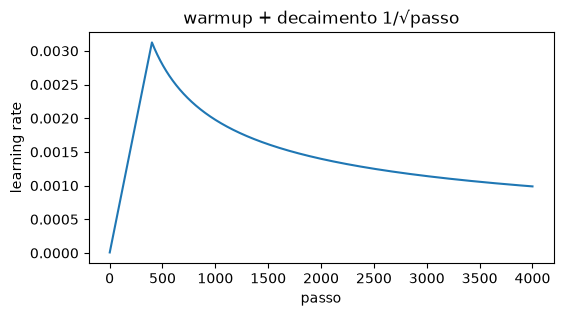

In [59]:
assert math.isclose(noam_lr(1, 512, 4000), 512 ** -0.5 * 4000 ** -1.5, rel_tol=1e-9)
peak = max(noam_lr(s, 512, 4000) for s in range(1, 20000))
assert math.isclose(noam_lr(4000, 512, 4000), peak, rel_tol=1e-9), "o pico deve ocorrer em step == warmup"
assert noam_lr(8000, 512, 4000) < peak
print("✅ lr schedule ok")

steps = range(1, cfg.steps + 1)
plt.figure(figsize=(6, 3))
plt.plot(steps, [cfg.lr_factor * noam_lr(s, cfg.d_model, cfg.warmup_steps) for s in steps])
plt.xlabel("passo"); plt.ylabel("learning rate"); plt.title("warmup + decaimento 1/√passo"); plt.show()

## 12. Geração (greedy) e avaliação

Treino é paralelo (teacher forcing); a **geração** é sequencial: encode uma vez, depois gere um token por vez, realimentando o que foi gerado. Aqui sem KV-cache (reprocessa o prefixo a cada passo), que é simples e suficiente para o toy.

A função `evaluate` (já pronta) reporta, na validação: **CE** sem suavização e perplexidade, **acurácia por token** (com teacher forcing) e **exact match** (sequência inteira gerada por greedy decode). Exact match é a métrica que importa nesta tarefa.

In [60]:
@torch.no_grad()
def greedy_decode(model, src, max_new=None):
    """Retorna [B, T] começando em BOS. Para quando todas as sequências já emitiram EOS ou ao atingir max_new."""
    # TODO: src_mask = make_padding_mask(src); memory = model.encode(src, src_mask) UMA vez;
    #       ys = BOS; repetir: logits = model.decode(memory, src_mask, ys, make_tgt_mask(ys))[:, -1];
    #       próximo = argmax; concatenar a ys; parar se todas tiverem EOS
    model = model.to(device)
    src = src.to(device)
    src_mask = make_padding_mask(src)
    memory = model.encode(src, src_mask)
    ys = torch.full((src.size(0), 1), BOS, dtype=torch.long, device=src.device)
    for _ in range(max_new or 100):
        tgt_mask = make_tgt_mask(ys)
        logits = model.decode(memory, src_mask, ys, tgt_mask)[:, -1]
        next_token = logits.argmax(dim=-1, keepdim=True)
        ys = torch.cat([ys, next_token], dim=1)
        if (next_token == EOS).all():
            break
    return ys


@torch.no_grad()
def evaluate(model, examples, bs=250):
    model = model.to(device)
    model.eval()
    tot_loss, tot_tok, correct_tok, exact = 0.0, 0, 0, 0
    for i in range(0, len(examples), bs):
        chunk = examples[i:i + bs]
        src, tgt_in, tgt_out = [t.to(device) for t in collate(chunk)]
        logits = model(src, tgt_in)
        mask = tgt_out != PAD
        tot_loss += F.cross_entropy(logits[mask], tgt_out[mask], reduction="sum").item()
        tot_tok += mask.sum().item()
        correct_tok += (logits.argmax(-1)[mask] == tgt_out[mask]).sum().item()
        pred = greedy_decode(model, src, max_new=tgt_out.size(1))
        for b, (s, t) in enumerate(chunk):
            p = pred[b, 1:].tolist()                       # remove BOS
            p = p[:p.index(EOS)] if EOS in p else p
            exact += int(p == t)
    model.train()
    ce = tot_loss / tot_tok
    return {"loss": ce, "ppl": math.exp(ce), "tok_acc": correct_tok / tot_tok, "exact": exact / len(examples)}

In [61]:
model.eval()
out = greedy_decode(model, src, max_new=5)
assert out.size(0) == src.size(0) and out.size(1) <= 6 and (out[:, 0] == BOS).all()
print("✅ greedy decode (forma) ok | modelo sem treino, exact match:", evaluate(model, [make_example(3, 8) for _ in range(50)])["exact"])

✅ greedy decode (forma) ok | modelo sem treino, exact match: 0.0


## 13. Treino

Passos do loop (já implementado): forward paralelo com teacher forcing → label smoothing → backward → **clip de gradiente** (prática moderna, não está no paper) → Adam com β=(0.9, 0.98), ε=1e-9 → scheduler de warmup.

**Antes de treinar de verdade, rode o teste de sanidade "overfit em um batch":** a loss deve cair para perto de zero. Se não cair, o problema está no modelo, na loss ou no otimizador, e não nos dados.

In [62]:
def train(cfg, log_every=250, seed=0):
    set_seed(seed)
    data = Data(cfg)
    model = Transformer(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg.lr_factor, betas=(0.9, 0.98), eps=1e-9)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: noam_lr(s + 1, cfg.d_model, cfg.warmup_steps))
    hist = {"step": [], "train_loss": [], "val_loss": [], "val_acc": [], "val_exact": []}
    t0 = time.time()
    for step in range(1, cfg.steps + 1):
        model.train()
        src, tgt_in, tgt_out = data.train_batch()
        logits = model(src, tgt_in)
        loss = label_smoothing_loss(logits.reshape(-1, VOCAB), tgt_out.reshape(-1), eps=cfg.label_smoothing)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        if step == 1 or step % log_every == 0:
            m = evaluate(model, data.val)
            for k, v in zip(hist, [step, loss.item(), m["loss"], m["tok_acc"], m["exact"]]):
                hist[k].append(v)
            print(f"step {step:5d} | lr {sched.get_last_lr()[0]:.2e} | train {loss.item():.3f} | "
                  f"val CE {m['loss']:.3f} | tok acc {m['tok_acc']:.3f} | exact {m['exact']:.3f} | {time.time() - t0:.0f}s")
    return model, data, hist


def overfit_one_batch(cfg, steps=400):
    """Sanidade: decorar 16 exemplos. A loss deve ir para perto de 0."""
    set_seed(0)
    model = Transformer(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    src, tgt_in, tgt_out = [t.to(device) for t in collate([make_example(cfg.min_len, cfg.max_len) for _ in range(16)])]
    for i in range(steps):
        loss = F.cross_entropy(model(src, tgt_in).reshape(-1, VOCAB), tgt_out.reshape(-1), ignore_index=PAD)
        opt.zero_grad(); loss.backward(); opt.step()
        if i % 100 == 0 or i == steps - 1:
            print(f"passo {i:4d} | loss {loss.item():.4f}")

In [63]:
overfit_one_batch(Config(dropout=0.0))   # a loss deve cair de ~2.5 para perto de 0

passo    0 | loss 3.4550
passo  100 | loss 0.0039
passo  200 | loss 0.0016
passo  300 | loss 0.0010
passo  399 | loss 0.0007


In [64]:
model, data, hist = train(cfg)

step     1 | lr 1.56e-05 | train 3.401 | val CE 3.443 | tok acc 0.081 | exact 0.000 | 1s
step   250 | lr 1.96e-03 | train 1.292 | val CE 0.522 | tok acc 0.858 | exact 0.434 | 8s
step   500 | lr 2.79e-03 | train 0.754 | val CE 0.108 | tok acc 0.984 | exact 0.880 | 14s
step   750 | lr 2.28e-03 | train 0.678 | val CE 0.091 | tok acc 0.992 | exact 0.938 | 21s
step  1000 | lr 1.98e-03 | train 0.603 | val CE 0.076 | tok acc 1.000 | exact 1.000 | 27s
step  1250 | lr 1.77e-03 | train 0.587 | val CE 0.079 | tok acc 0.999 | exact 0.992 | 34s
step  1500 | lr 1.61e-03 | train 0.569 | val CE 0.078 | tok acc 1.000 | exact 1.000 | 41s
step  1750 | lr 1.49e-03 | train 0.580 | val CE 0.077 | tok acc 1.000 | exact 0.998 | 47s
step  2000 | lr 1.40e-03 | train 0.585 | val CE 0.078 | tok acc 0.999 | exact 0.988 | 54s
step  2250 | lr 1.32e-03 | train 0.571 | val CE 0.077 | tok acc 1.000 | exact 1.000 | 60s
step  2500 | lr 1.25e-03 | train 0.556 | val CE 0.078 | tok acc 1.000 | exact 1.000 | 67s
step  2750 |

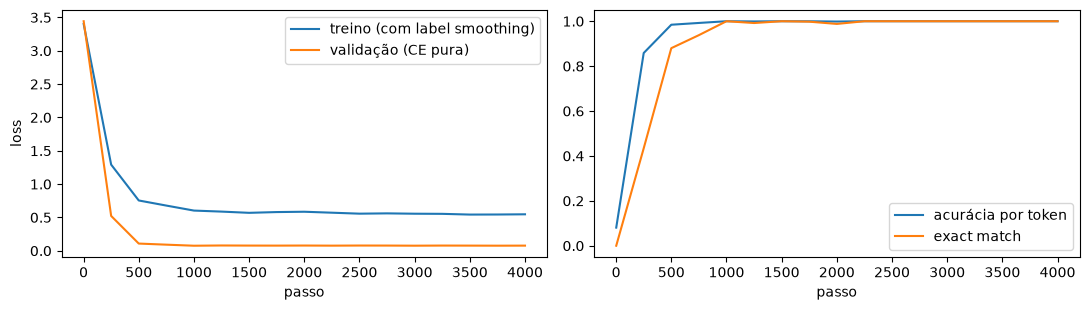

In [65]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(hist["step"], hist["train_loss"], label="treino (com label smoothing)")
ax[0].plot(hist["step"], hist["val_loss"], label="validação (CE pura)")
ax[0].set_xlabel("passo"); ax[0].set_ylabel("loss"); ax[0].legend()
ax[1].plot(hist["step"], hist["val_acc"], label="acurácia por token")
ax[1].plot(hist["step"], hist["val_exact"], label="exact match")
ax[1].set_xlabel("passo"); ax[1].legend()
plt.tight_layout(); plt.show()

## 14. Olhando a atenção

Na inversão, a linha que gera o token `t_i` deve olhar para a posição `n-1-i` da fonte, formando uma **anti-diagonal**. Compare cabeças e camadas: algumas serão nítidas, outras redundantes ou difusas.

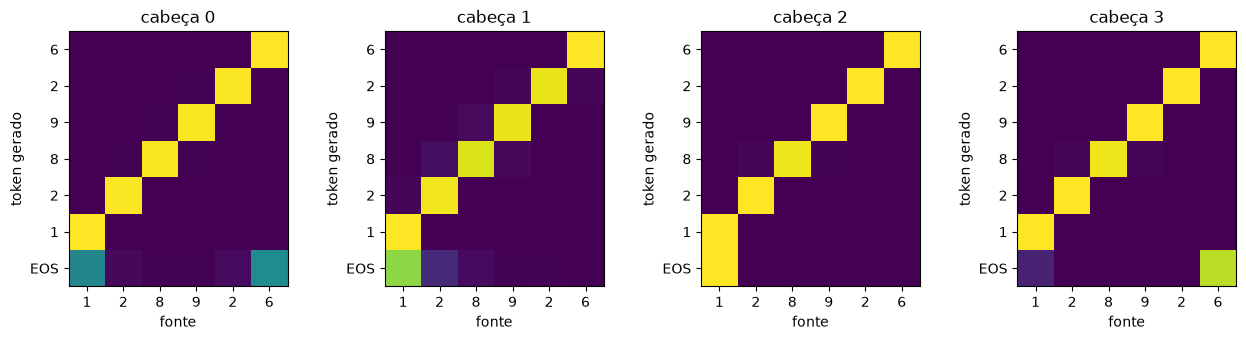

In [66]:
@torch.no_grad()
def show_cross_attention(model, example, layer=-1):
    model.eval()
    s, t = example
    src, tgt_in, _ = [x.to(device) for x in collate([example])]
    model(src, tgt_in)
    attn = model.decoder.layers[layer].cross_attn.attn[0].cpu()      # [h, T, S]
    h = attn.size(0)
    fig, axes = plt.subplots(1, h, figsize=(3.2 * h, 3.4))
    for i, ax in enumerate(np.atleast_1d(axes)):
        ax.imshow(attn[i], cmap="viridis", vmin=0, vmax=1)
        ax.set_title(f"cabeça {i}")
        ax.set_xticks(range(len(s))); ax.set_xticklabels([str(x - 3) for x in s])
        ax.set_yticks(range(len(t) + 1)); ax.set_yticklabels([str(x - 3) for x in t] + ["EOS"])
        ax.set_xlabel("fonte"); ax.set_ylabel("token gerado")
    plt.tight_layout(); plt.show()

show_cross_attention(model, make_example(6, 8))

## 15. Experimentos: onde o aprendizado acontece

Cada linha muda **uma** coisa. Antes de rodar, escreva sua previsão; depois compare. As colunas "tipicamente" são expectativas, não garantias: se o resultado for diferente, investigar o porquê é o exercício.

| # | Conceito | O que mudar | Tipicamente você vê |
|---|---|---|---|
| 1 | Masking (causal) | Em `make_tgt_mask`, remover a parte causal | Loss de treino cai muito rápido, mas o exact match na geração fica perto de 0: o modelo "colava" |
| 2 | Masking (padding) | Remover `make_padding_mask` da fonte | Degradação pequena aqui; o teste "padding da fonte ok" da seção 9 passa a falhar |
| 3 | Escala √d_k | Tirar a divisão em `scaled_dot_product_attention` | Efeito sutil com d_k=16; use `d_model=512, n_heads=1` para ver o treino piorar |
| 4 | Multi-head | `n_heads` = 1, 2, 4, 8 (d_model=64) | Compare os mapas de atenção da seção 14: cabeças redundantes vs. especializadas |
| 5 | Residual | Em `SublayerConnection`, tirar a soma com `x` | Treino emperra, ainda mais com `n_layers` maior (6) |
| 6 | LayerNorm | Trocar por identidade | Treino instável ou mais lento; teste LR menor |
| 7 | Post-LN vs pre-LN | `pre_norm=True`; depois `warmup_steps=1` nos dois | Post-LN sem warmup tende a divergir; pre-LN aguenta melhor |
| 8 | Dropout | `dropout=0.0` vs `0.1`, com `train_size=2000` | Sem dropout, a diferença treino/validação cresce em dados finitos |
| 9 | Label smoothing | `label_smoothing=0.0` vs `0.1` | CE/perplexidade de validação **pior** com smoothing; acurácia/exact igual ou melhor (como diz o paper) |
| 10 | Extrapolação | Treinar em 3-12, testar em 13-16 | Degrada: a codificação sinusoidal não garante generalizar para comprimentos nunca vistos |

In [67]:
# Exemplo: dropout, label smoothing e pre-LN em dados FINITOS (onde há overfitting)
results = {}
for name, kw in {
    "base":             dict(train_size=2000),
    "sem dropout":      dict(train_size=2000, dropout=0.0),
    "sem label smooth": dict(train_size=2000, label_smoothing=0.0),
    "pre-LN":           dict(train_size=2000, pre_norm=True),
}.items():
    print("\n==", name)
    m, d, h = train(Config(**kw), log_every=1000)
    results[name] = evaluate(m, d.val)

print()
for name, r in results.items():
    print(f"{name:18s} | val CE {r['loss']:.3f} | ppl {r['ppl']:.2f} | tok acc {r['tok_acc']:.3f} | exact {r['exact']:.3f}")


== base
step     1 | lr 1.56e-05 | train 3.428 | val CE 3.443 | tok acc 0.081 | exact 0.000 | 0s
step  1000 | lr 1.98e-03 | train 0.596 | val CE 0.089 | tok acc 0.995 | exact 0.958 | 26s
step  2000 | lr 1.40e-03 | train 0.565 | val CE 0.078 | tok acc 1.000 | exact 1.000 | 51s
step  3000 | lr 1.14e-03 | train 0.568 | val CE 0.079 | tok acc 1.000 | exact 1.000 | 76s
step  4000 | lr 9.88e-04 | train 0.550 | val CE 0.079 | tok acc 1.000 | exact 1.000 | 101s

== sem dropout
step     1 | lr 1.56e-05 | train 3.506 | val CE 3.442 | tok acc 0.081 | exact 0.000 | 0s
step  1000 | lr 1.98e-03 | train 0.565 | val CE 0.116 | tok acc 0.995 | exact 0.960 | 24s
step  2000 | lr 1.40e-03 | train 0.538 | val CE 0.112 | tok acc 0.995 | exact 0.960 | 48s
step  3000 | lr 1.14e-03 | train 0.537 | val CE 0.097 | tok acc 1.000 | exact 1.000 | 72s
step  4000 | lr 9.88e-04 | train 0.537 | val CE 0.099 | tok acc 0.999 | exact 0.994 | 96s

== sem label smooth
step     1 | lr 1.56e-05 | train 3.424 | val CE 3.443 |

## Próximos passos

1. **Dados reais:** tradução pequena (Multi30k) com `datasets` e `tokenizers` da Hugging Face (BPE), avaliando com BLEU via `sacrebleu`.
2. **Decoder-only (GPT):** remova o encoder e a cross-attention; o objetivo vira prever o próximo token. É o que a Assignment 1 do CS336 pede, e a aula 13 da UFC descreve.
3. **Modernizar o bloco:** RMSNorm no lugar de LayerNorm, RoPE no lugar da PE sinusoidal, SwiGLU no lugar da FFN com ReLU (CS336, aula 3).
4. **Engenharia:** logging com TensorBoard ou Weights & Biases, `torch.compile`, precisão mista (`torch.autocast` com bf16) e KV-cache na geração.